In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    log_loss
)


In [58]:
df = pd.read_csv("bank.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (11162, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


In [59]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        11162 non-null  int64 
 1   job        11162 non-null  object
 2   marital    11162 non-null  object
 3   education  11162 non-null  object
 4   default    11162 non-null  object
 5   balance    11162 non-null  int64 
 6   housing    11162 non-null  object
 7   loan       11162 non-null  object
 8   contact    11162 non-null  object
 9   day        11162 non-null  int64 
 10  month      11162 non-null  object
 11  duration   11162 non-null  int64 
 12  campaign   11162 non-null  int64 
 13  pdays      11162 non-null  int64 
 14  previous   11162 non-null  int64 
 15  poutcome   11162 non-null  object
 16  deposit    11162 non-null  object
dtypes: int64(7), object(10)
memory usage: 1.4+ MB


In [60]:
df.isnull().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
deposit      0
dtype: int64

In [61]:
df.duplicated().sum()

np.int64(0)

In [62]:
df["deposit"].value_counts()

deposit
no     5873
yes    5289
Name: count, dtype: int64

## Exploratory Data Analysis(EDA)

In [63]:
df.shape

(11162, 17)

In [64]:
df.columns.tolist()

['age',
 'job',
 'marital',
 'education',
 'default',
 'balance',
 'housing',
 'loan',
 'contact',
 'day',
 'month',
 'duration',
 'campaign',
 'pdays',
 'previous',
 'poutcome',
 'deposit']

In [65]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000
mean,41.231948,1528.538524,15.658036,371.993818,2.508421,51.330407,0.832557
std,11.913369,3225.413326,8.420740,347.128386,2.722077,108.758282,2.292007
min,18.000000,-6847.000000,1.000000,2.000000,1.000000,-1.000000,0.000000
25%,32.000000,122.000000,8.000000,138.000000,1.000000,-1.000000,0.000000
50%,39.000000,550.000000,15.000000,255.000000,2.000000,-1.000000,0.000000
75%,49.000000,1708.000000,22.000000,496.000000,3.000000,20.750000,1.000000
max,95.000000,81204.000000,31.000000,3881.000000,63.000000,854.000000,58.000000


In [66]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values: 0
Duplicate rows: 0


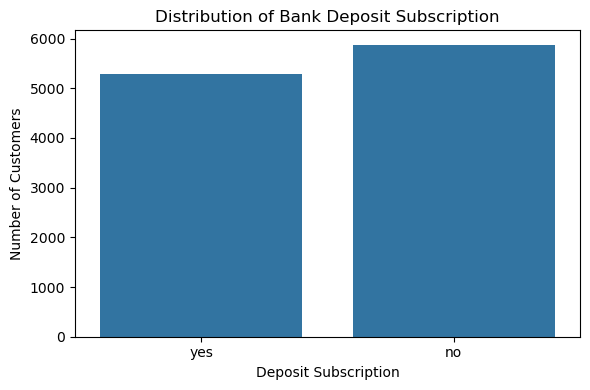

In [67]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="deposit")

plt.title("Distribution of Bank Deposit Subscription")
plt.xlabel("Deposit Subscription")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

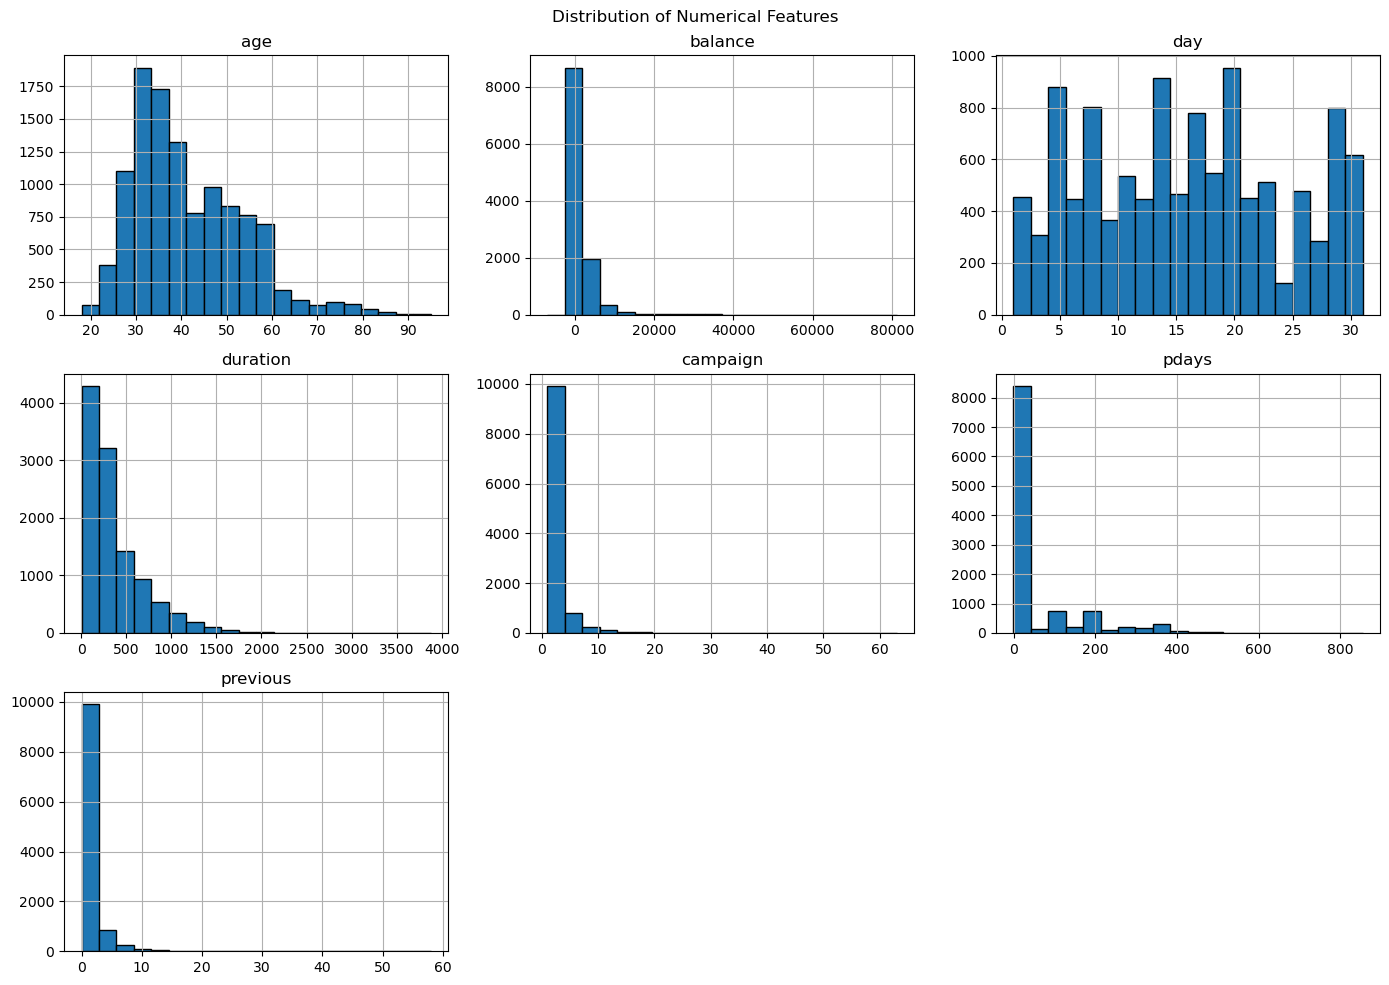

In [68]:
numerical_columns = df.select_dtypes(include=np.number).columns

df[numerical_columns].hist(
    figsize=(14, 10),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

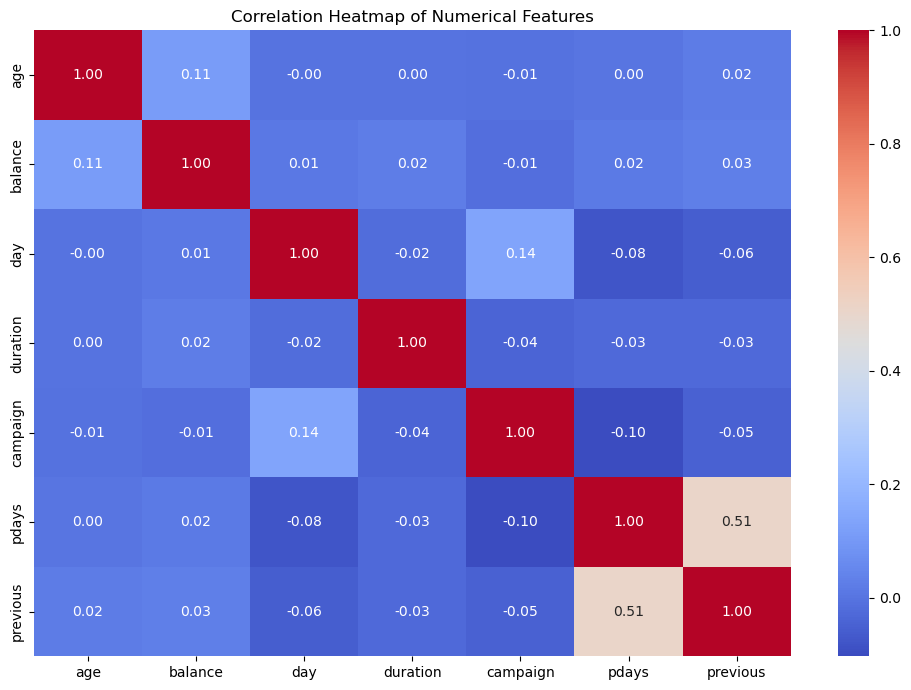

In [69]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df[numerical_columns].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

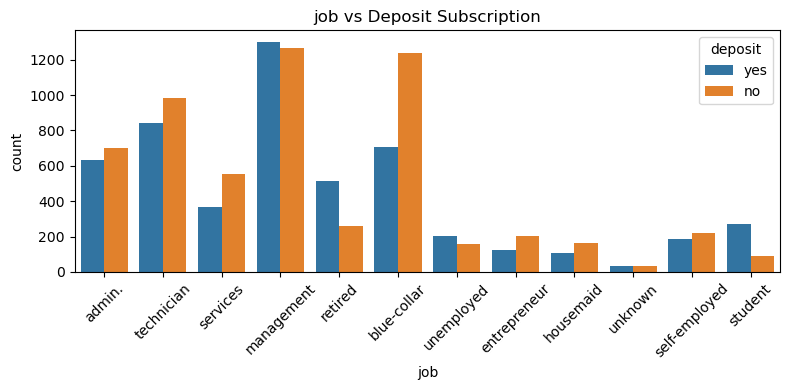

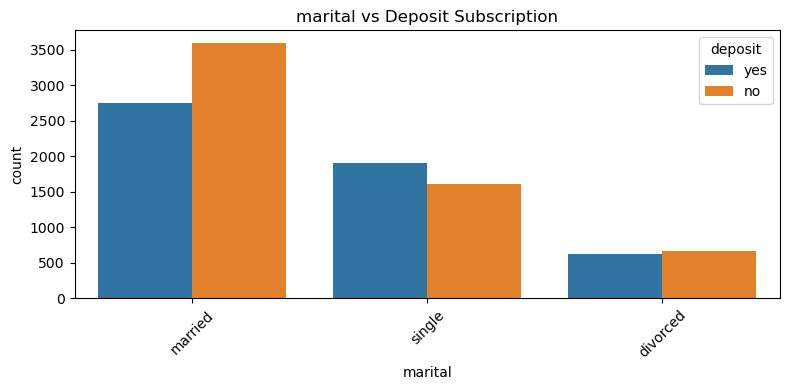

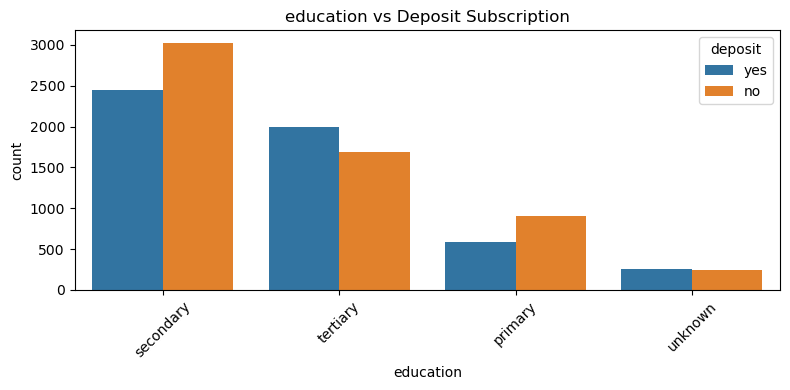

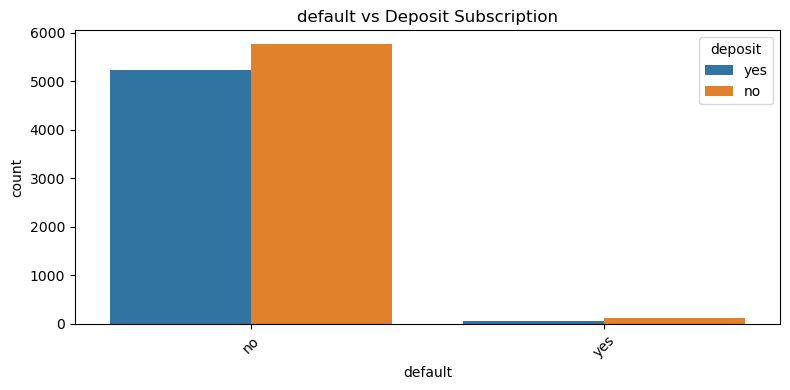

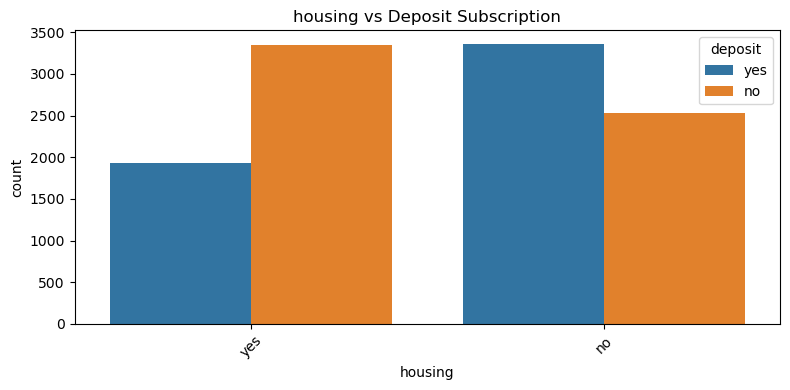

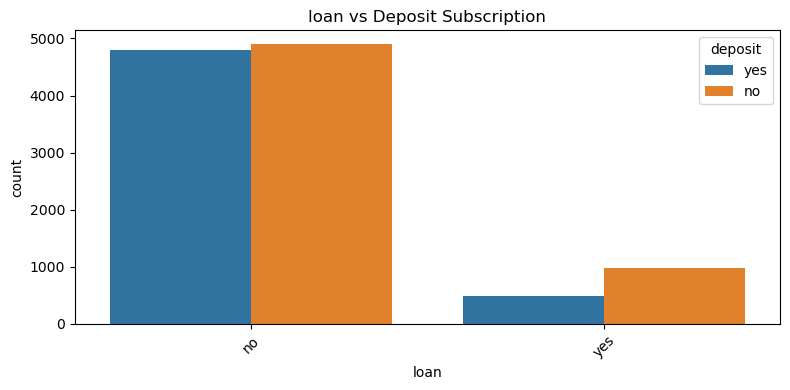

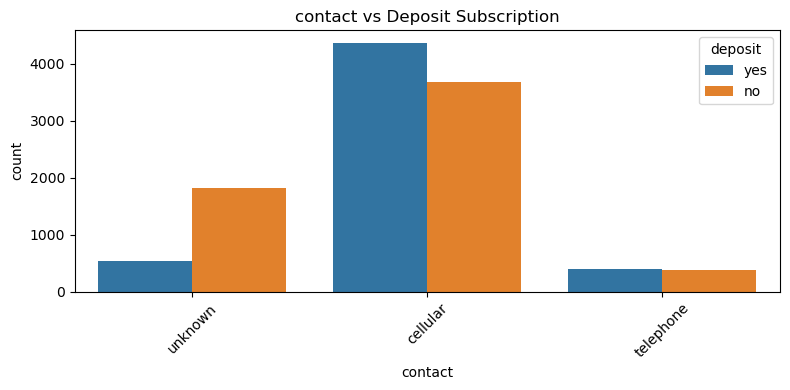

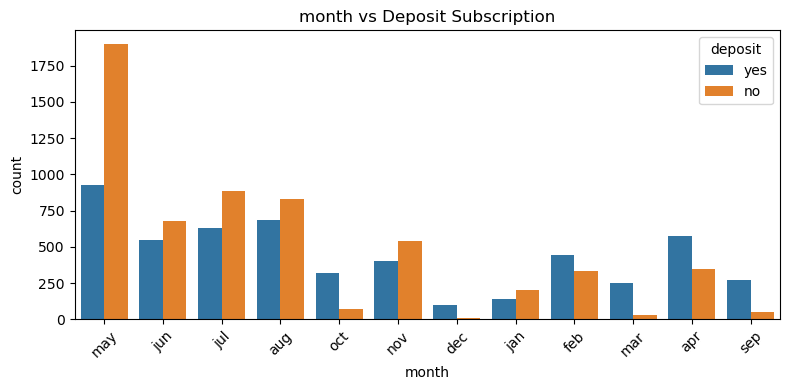

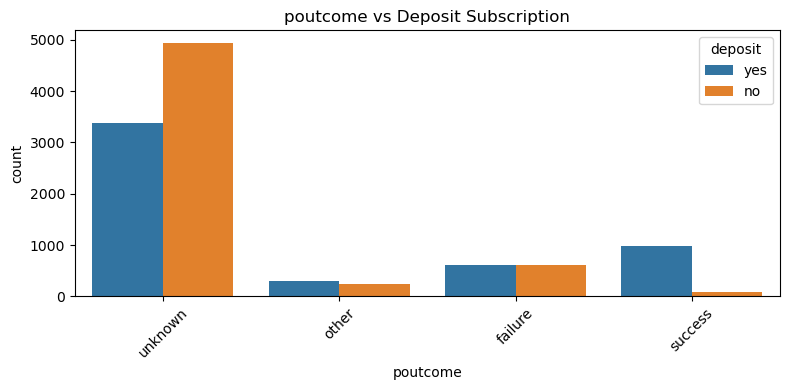

In [70]:
categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

categorical_columns = [
    col for col in categorical_columns if col != "deposit"
]

for col in categorical_columns:
    plt.figure(figsize=(8, 4))

    sns.countplot(
        data=df,
        x=col,
        hue="deposit"
    )

    plt.title(f"{col} vs Deposit Subscription")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()



### Data Preparation

In [71]:

# Separate features and target
X = df.drop(columns=["deposit", "duration"], errors="ignore")
y = df["deposit"].map({"no": 0, "yes": 1})

# Convert categorical columns into numeric columns
X = pd.get_dummies(X, drop_first=True)

# Scale the features
scaler = StandardScaler()
X = pd.DataFrame(scaler.fit_transform(X), columns=X.columns, index=X.index)

# Train-test split ratios
splits = {
    "80:20": 0.20,
    "70:30": 0.30,
    "75:25": 0.25
}

print("Data preparation completed!")
print("Features:", X.shape)
print("Target:", y.shape)

Data preparation completed!
Features: (11162, 41)
Target: (11162,)


### Logistic Regression

In [72]:
lr_results = []

for name, test_size in splits.items():
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=42, stratify=y
    )

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    model = LogisticRegression(max_iter=1000)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    lr_results.append({
        "Algorithm": "Logistic Regression",
        "Split": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0)
    })

    print("\nLogistic Regression -", name)
    print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
    print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
    print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
    print("F1-Score:", round(f1_score(y_test, y_pred, zero_division=0), 4))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

lr_results = pd.DataFrame(lr_results)


Logistic Regression - 80:20
Accuracy: 0.695
Precision: 0.7324
Recall: 0.5614
F1-Score: 0.6356
Confusion Matrix:
 [[958 217]
 [464 594]]

Logistic Regression - 70:30
Accuracy: 0.6987
Precision: 0.7396
Recall: 0.5621
F1-Score: 0.6387
Confusion Matrix:
 [[1448  314]
 [ 695  892]]

Logistic Regression - 75:25
Accuracy: 0.6983
Precision: 0.739
Recall: 0.5613
F1-Score: 0.638
Confusion Matrix:
 [[1207  262]
 [ 580  742]]


### Decision Tree Classifier

In [73]:
dt_results = []

for name, test_size in splits.items():
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=42, stratify=y
    )

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    model = DecisionTreeClassifier(random_state=42)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    dt_results.append({
        "Algorithm": "Decision Tree",
        "Split": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0)
    })

    print("\nDecision Tree -", name)
    print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
    print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
    print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
    print("F1-Score:", round(f1_score(y_test, y_pred, zero_division=0), 4))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

dt_results = pd.DataFrame(dt_results)


Decision Tree - 80:20
Accuracy: 0.6426
Precision: 0.6229
Recall: 0.6229
F1-Score: 0.6229
Confusion Matrix:
 [[776 399]
 [399 659]]

Decision Tree - 70:30
Accuracy: 0.6163
Precision: 0.5956
Recall: 0.5929
F1-Score: 0.5943
Confusion Matrix:
 [[1123  639]
 [ 646  941]]

Decision Tree - 75:25
Accuracy: 0.6256
Precision: 0.6053
Recall: 0.6021
F1-Score: 0.6037
Confusion Matrix:
 [[950 519]
 [526 796]]


### Random Forest Classifier

In [74]:
rf_results = []

for name, test_size in splits.items():
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=42, stratify=y
    )

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    model = RandomForestClassifier(n_estimators=100, random_state=42)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    rf_results.append({
        "Algorithm": "Random Forest",
        "Split": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0)
    })

    print("\nRandom Forest -", name)
    print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
    print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
    print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
    print("F1-Score:", round(f1_score(y_test, y_pred, zero_division=0), 4))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

rf_results = pd.DataFrame(rf_results)


Random Forest - 80:20
Accuracy: 0.7282
Precision: 0.7548
Recall: 0.6314
F1-Score: 0.6876
Confusion Matrix:
 [[958 217]
 [390 668]]

Random Forest - 70:30
Accuracy: 0.7247
Precision: 0.7487
Recall: 0.6307
F1-Score: 0.6847
Confusion Matrix:
 [[1426  336]
 [ 586 1001]]

Random Forest - 75:25
Accuracy: 0.7266
Precision: 0.7493
Recall: 0.6354
F1-Score: 0.6877
Confusion Matrix:
 [[1188  281]
 [ 482  840]]


### K-Nearest Neighbors (KNN)

In [75]:
knn_results = []

for name, test_size in splits.items():
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=42, stratify=y
    )

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    model = KNeighborsClassifier(n_neighbors=5)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    knn_results.append({
        "Algorithm": "KNN",
        "Split": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0)
    })

    print("\nKNN -", name)
    print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
    print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
    print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
    print("F1-Score:", round(f1_score(y_test, y_pred, zero_division=0), 4))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

knn_results = pd.DataFrame(knn_results)


KNN - 80:20
Accuracy: 0.6811
Precision: 0.686
Recall: 0.603
F1-Score: 0.6419
Confusion Matrix:
 [[883 292]
 [420 638]]

KNN - 70:30
Accuracy: 0.6829
Precision: 0.6876
Recall: 0.6062
F1-Score: 0.6443
Confusion Matrix:
 [[1325  437]
 [ 625  962]]

KNN - 75:25
Accuracy: 0.6836
Precision: 0.6878
Recall: 0.6082
F1-Score: 0.6455
Confusion Matrix:
 [[1104  365]
 [ 518  804]]


### Support Vector Machine (SVM)

In [76]:
svm_results = []

for name, test_size in splits.items():
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=42, stratify=y
    )

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    model = SVC(kernel="rbf", random_state=42)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    svm_results.append({
        "Algorithm": "SVM",
        "Split": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0)
    })

    print("\nSVM -", name)
    print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
    print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
    print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
    print("F1-Score:", round(f1_score(y_test, y_pred, zero_division=0), 4))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

svm_results = pd.DataFrame(svm_results)


SVM - 80:20
Accuracy: 0.7268
Precision: 0.7909
Recall: 0.5756
F1-Score: 0.6663
Confusion Matrix:
 [[1014  161]
 [ 449  609]]

SVM - 70:30
Accuracy: 0.7268
Precision: 0.7973
Recall: 0.5677
F1-Score: 0.6632
Confusion Matrix:
 [[1533  229]
 [ 686  901]]

SVM - 75:25
Accuracy: 0.7266
Precision: 0.7896
Recall: 0.5764
F1-Score: 0.6664
Confusion Matrix:
 [[1266  203]
 [ 560  762]]


### Comparison between all algorithms

In [77]:
# Combine all results
all_results = pd.concat([
    lr_results,
    dt_results,
    rf_results,
    knn_results,
    svm_results
], ignore_index=True)

# Display comparison table
print("Comparison of All Algorithms")
display(all_results.round(4))

Comparison of All Algorithms


,Algorithm,Split,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,80:20,0.6950,0.7324,0.5614,0.6356
1,Logistic Regression,70:30,0.6987,0.7396,0.5621,0.6387
2,Logistic Regression,75:25,0.6983,0.7390,0.5613,0.6380
3,Decision Tree,80:20,0.6426,0.6229,0.6229,0.6229
4,Decision Tree,70:30,0.6163,0.5956,0.5929,0.5943
5,Decision Tree,75:25,0.6256,0.6053,0.6021,0.6037
6,Random Forest,80:20,0.7282,0.7548,0.6314,0.6876
7,Random Forest,70:30,0.7247,0.7487,0.6307,0.6847
8,Random Forest,75:25,0.7266,0.7493,0.6354,0.6877
9,KNN,80:20,0.6811,0.6860,0.6030,0.6419


### Accuracy comparison chart

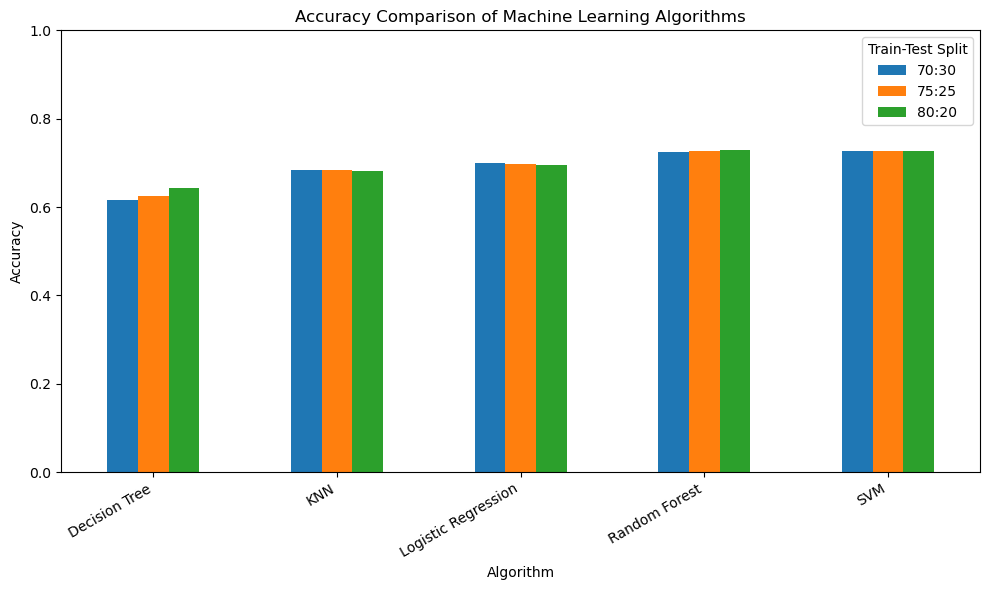

In [78]:

pivot_data = all_results.pivot(
    index="Algorithm",
    columns="Split",
    values="Accuracy"
)

pivot_data.plot(kind="bar", figsize=(10, 6))

plt.title("Accuracy Comparison of Machine Learning Algorithms")
plt.xlabel("Algorithm")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.legend(title="Train-Test Split")
plt.tight_layout()
plt.show()